# Exploratory Data Analysis: Open Court Analytics

This notebook explains **why the pipeline makes the choices it does**. It covers three data layers:

| Section | Layer | Question |
|---|---|---|
| 1 | Raw events (`raw_court_events`) | What is wrong with the raw extract, and why do we clean it? |
| 2 | Case warehouse (`v_analyst_cases`, `v_public_*`) | Who files, where, how fast, and what distorts timelines? |
| 3 | Gold set (`gold_court_orders.jsonl`) | What does the court-order extraction task look like? |
| 4 | Takeaways | Which modeling decision does each finding drive? |

Model results (KM tables, Cox/logit coefficients, benchmark F1) live in the [brief](../reports/court_data_brief.qmd) and the dashboard, not here.

**Privacy:** this notebook is written to be published. Only aggregates are shown. Every eviction-record count below 10 is suppressed, along with any rate built from it. Raw case numbers, tenant city and ZIP are never displayed.

**Charts:** interactive in Jupyter/VS Code (hover, zoom, click legend items to toggle). On GitHub each chart falls back to an embedded PNG.

In [1]:
import importlib.util
import json
import re
from pathlib import Path

import duckdb
import geopandas as gpd
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from lifelines import KaplanMeierFitter
from plotly.subplots import make_subplots

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
con = duckdb.connect(str(ROOT / "data/processed/court_warehouse.duckdb"), read_only=True)
q = lambda sql: con.sql(sql).df()

# Reuse the repo's governance check (module name starts with a digit, so load it by path)
_spec = importlib.util.spec_from_file_location("export_tableau", ROOT / "src/analytics/04_export_tableau.py")
_mod = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(_mod)
assert_public_safe = _mod.assert_public_safe

K = 10  # small-cell suppression threshold, same as sql/03_pii_governance_views.sql

def suppress(df, cols):
    """Null out any count < K (the rates computed from them are masked separately)."""
    df = df.copy()
    for c in cols:
        df[c] = df[c].astype("Float64").mask(df[c] < K)
    return df

# Categorical slots in fixed order; each entity keeps one color across every chart
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
GRAY, INK, MUTED = "#c9c8c2", "#0b0b0b", "#52514e"
OUTCOME = {"Cancelled": BLUE, "Evicted": ORANGE, "Expired": AQUA, "Petition": YELLOW, "Pending": YELLOW}
BLUES = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

pio.templates["court"] = go.layout.Template(layout=dict(
    font=dict(family="Inter, Helvetica, Arial, sans-serif", size=13, color=INK),
    title=dict(font=dict(size=17), x=0.01, xanchor="left", yref="container", y=0.97, yanchor="top", automargin=True),
    paper_bgcolor="#fcfcfb", plot_bgcolor="#fcfcfb",
    colorway=[BLUE, ORANGE, AQUA, YELLOW, MAGENTA],
    xaxis=dict(gridcolor="#ebeae6", zeroline=False, linecolor=GRAY, tickfont=dict(color=MUTED)),
    yaxis=dict(gridcolor="#ebeae6", zeroline=False, linecolor=GRAY, tickfont=dict(color=MUTED)),
    legend=dict(orientation="h", yanchor="bottom", y=1.0, x=0, title=None, traceorder="normal"),
    hoverlabel=dict(bgcolor="white", font_size=13),
    barcornerradius=4, margin=dict(t=90, l=60, r=30, b=50),
))
pio.templates.default = "plotly_white+court"
# Interactive mimetype for Jupyter/VS Code; GitHub can't run plotly JS, so it shows the PNG from the same output
pio.renderers.default = "plotly_mimetype+png"
pio.renderers["png"].width = 1000

def subtitle(fig, title, sub):
    fig.update_layout(title=dict(text=title, subtitle=dict(text=sub, font=dict(size=13, color=MUTED))))
    return fig

## 1. Raw events: why we clean

The raw extract is **one row per court event**, not one row per case. The warehouse rolls events up to cases and then drops records that cannot support a timeline.

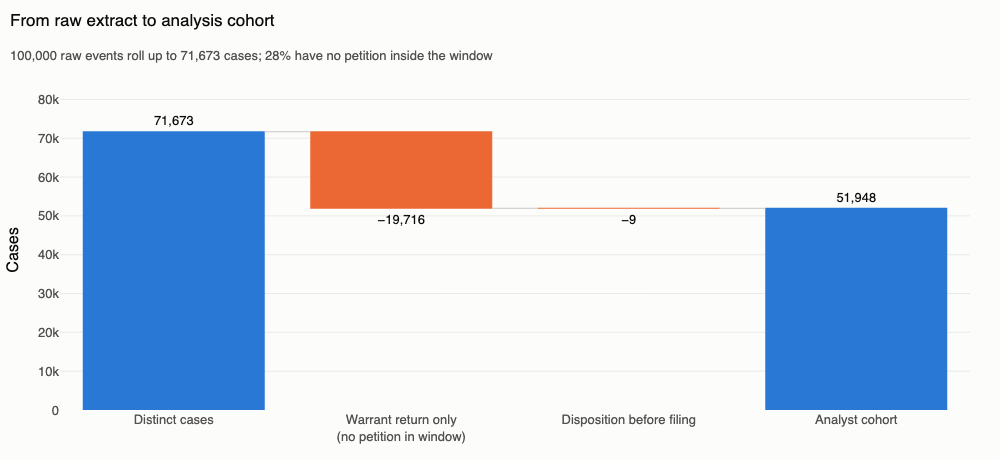

In [2]:
qa = q("SELECT metric, value FROM qa_audit_summary").set_index("metric")["value"]
raw_rows, n_cases = qa["raw_event_rows"], qa["distinct_cases_raw"]
trunc, impossible, cohort = qa["left_truncated_no_petition"], qa["impossible_date_cases"], qa["analyst_cohort_cases"]
assert n_cases - trunc - impossible == cohort, "QA audit counts do not reconcile"

fig = go.Figure(go.Waterfall(
    orientation="v",
    measure=["absolute", "relative", "relative", "total"],
    x=["Distinct cases", "Warrant return only<br>(no petition in window)", "Disposition before filing", "Analyst cohort"],
    y=[n_cases, -trunc, -impossible, cohort],
    text=[f"{n_cases:,}", f"−{trunc:,}", f"−{impossible:,}", f"{cohort:,}"], textposition="outside",
    connector=dict(line=dict(color=GRAY, width=1)),
    increasing=dict(marker_color=BLUE), decreasing=dict(marker_color=ORANGE), totals=dict(marker_color=BLUE),
    hovertemplate="%{x}<br>%{text} cases<extra></extra>",
))
fig.update_layout(height=460, yaxis_title="Cases", showlegend=False, yaxis_range=[0, n_cases * 1.15])
subtitle(fig, "From raw extract to analysis cohort",
         f"{raw_rows:,} raw events roll up to {n_cases:,} cases; {trunc / n_cases:.0%} have no petition inside the window")

**Left truncation.** A case whose first visible event is a warrant return had its petition filed *before* the extract window opened. We can't know its filing date, so it can't have a duration. If those dropped cases cluster at the start of the window, the gap comes from the extract, not from court behavior.

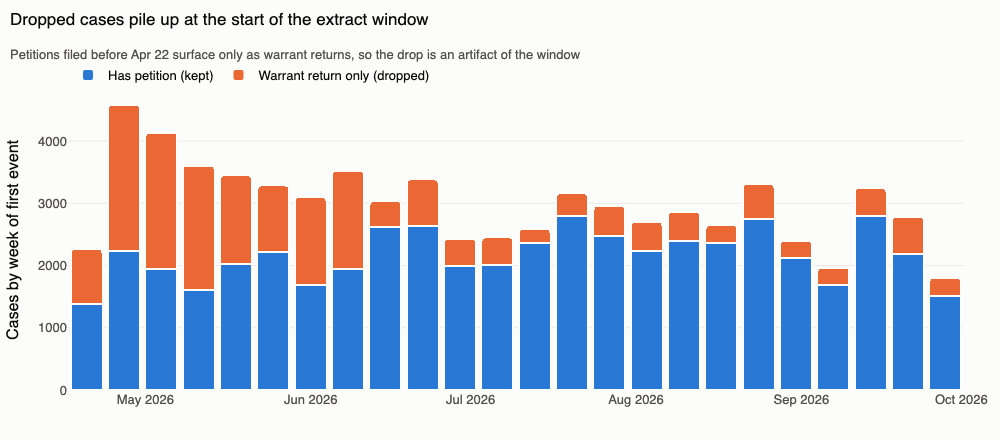

In [3]:
trunc_wk = q("""
    WITH c AS (
        SELECT clean_case_number,
               MIN(event_date) AS first_evt,
               BOOL_OR(raw_event_type ILIKE 'Petition%') AS has_petition
        FROM raw_court_events GROUP BY 1
    )
    SELECT DATE_TRUNC('week', first_evt) AS week,
           CASE WHEN has_petition THEN 'Has petition (kept)' ELSE 'Warrant return only (dropped)' END AS grp,
           COUNT(*) AS n
    FROM c GROUP BY 1, 2 ORDER BY 1
""")
trunc_wk = suppress(trunc_wk, ["n"])
assert_public_safe(trunc_wk, "trunc_wk", ["n"])

fig = go.Figure()
for grp, color in [("Has petition (kept)", BLUE), ("Warrant return only (dropped)", ORANGE)]:
    d = trunc_wk[trunc_wk.grp == grp]
    fig.add_bar(x=d.week, y=d.n, name=grp, marker=dict(color=color, line=dict(color="#fcfcfb", width=2)),
                hovertemplate="Week of %{x|%b %d}<br>%{y:,} cases<extra>" + grp + "</extra>")
fig.update_layout(barmode="stack", height=440, yaxis_title="Cases by week of first event", bargap=0.15)
subtitle(fig, "Dropped cases pile up at the start of the extract window",
         "Petitions filed before Apr 22 surface only as warrant returns, so the drop is an artifact of the window")

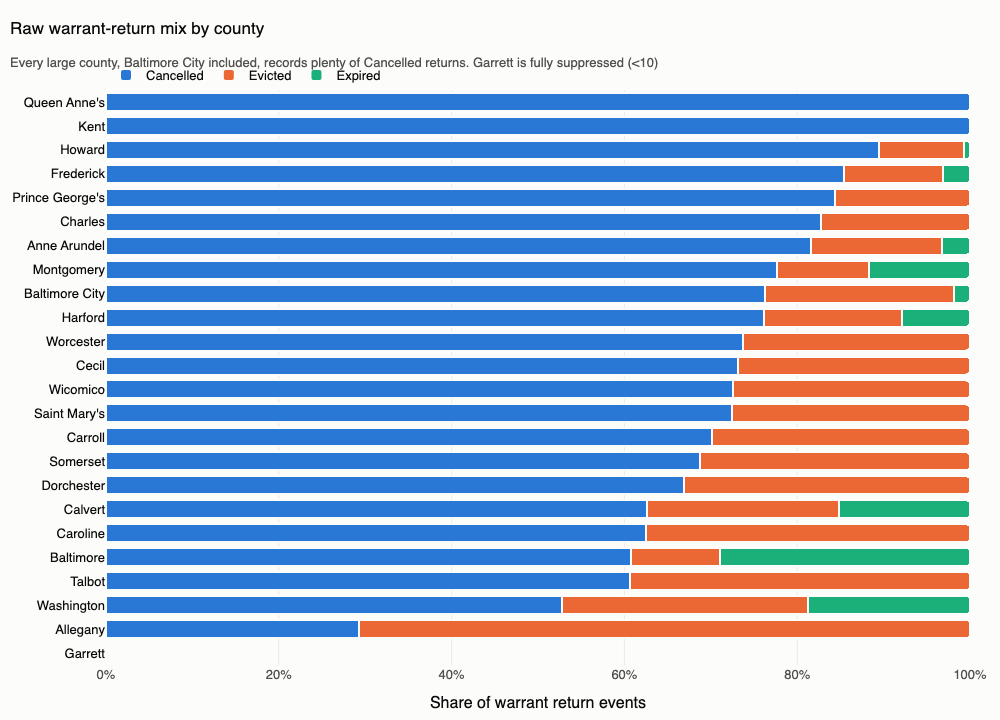

In [4]:
mix = q("""
    SELECT raw_county AS county,
           CASE WHEN raw_event_type ILIKE 'Petition%' THEN 'Petition'
                WHEN raw_event_type ILIKE '%Cancelled' THEN 'Cancelled'
                WHEN raw_event_type ILIKE '%Evicted'   THEN 'Evicted'
                WHEN raw_event_type ILIKE '%Expired'   THEN 'Expired' END AS event,
           COUNT(*) AS n
    FROM raw_court_events GROUP BY 1, 2
""")
# Fill missing combos with 0 so absent event types (e.g. zero 'Expired') show up, then suppress
mix = (mix.pivot(index="county", columns="event", values="n").fillna(0)
          .stack().rename("n").reset_index())
mix["share"] = mix.n / mix.groupby("county").n.transform("sum")
mix = suppress(mix, ["n"])
mix.loc[mix.n.isna(), "share"] = pd.NA
assert_public_safe(mix, "event_mix", ["n"])

returns = mix[mix.event != "Petition"].copy()
returns["share"] = returns.n / returns.groupby("county").n.transform("sum")  # share of warrant returns only
order = (returns[returns.event == "Cancelled"].sort_values("share", na_position="first").county.tolist())

fig = go.Figure()
for ev in ["Cancelled", "Evicted", "Expired"]:
    d = returns[returns.event == ev].set_index("county").reindex(order)
    fig.add_bar(y=d.index, x=d.share, name=ev, orientation="h",
                marker=dict(color=OUTCOME[ev], line=dict(color="#fcfcfb", width=2)),
                hovertemplate="%{y}<br>" + ev + ": %{x:.1%}<extra></extra>")
fig.update_layout(barmode="stack", height=720, bargap=0.25, yaxis=dict(tickfont=dict(color=INK)),
                  xaxis=dict(tickformat=".0%", title="Share of warrant return events", range=[0, 1]))
subtitle(fig, "Raw warrant-return mix by county",
         "Every large county, Baltimore City included, records plenty of Cancelled returns. Garrett is fully suppressed (<10)")

In [5]:
dups = q("""
    WITH g AS (
        SELECT raw_event_type, COUNT(*) AS cnt
        FROM raw_court_events
        GROUP BY raw_case_number, clean_case_number, event_date, evicted_date, raw_event_type, event_comment,
                 raw_county, court_location, raw_case_type, tenant_city_raw, tenant_state_raw, tenant_zip_raw,
                 event_year, eviction_year
    )
    SELECT raw_event_type AS event_type, SUM(cnt - 1) AS duplicate_rows FROM g WHERE cnt > 1 GROUP BY 1 ORDER BY 2 DESC
""")
dups = suppress(dups, ["duplicate_rows"])
assert_public_safe(dups, "dups", ["duplicate_rows"])
print(f"Exact duplicate event rows: {int(dups.duplicate_rows.sum()):,} of {raw_rows:,} "
      f"({dups.duplicate_rows.sum() / raw_rows:.1%})  |  messy case numbers normalized: {qa['messy_case_numbers_cleaned']}")
dups

Exact duplicate event rows: 1,007 of 100,000 (1.0%)  |  messy case numbers normalized: 7


,event_type,duplicate_rows
0,Petition - For Warrant of Restitution Filed,690.0
1,Warrant of Restitution - Return of Service - C...,292.0
2,Warrant of Restitution - Return of Service - E...,25.0


**Return-to-petition linkage.** The raw mix above looks normal, yet in the case cohort Baltimore City shows almost no Cancelled or Expired outcomes (see Section 2). The case number encodes the filing year (`D-01-LT-25-…` means 2025). That shows where the city's returns actually go.

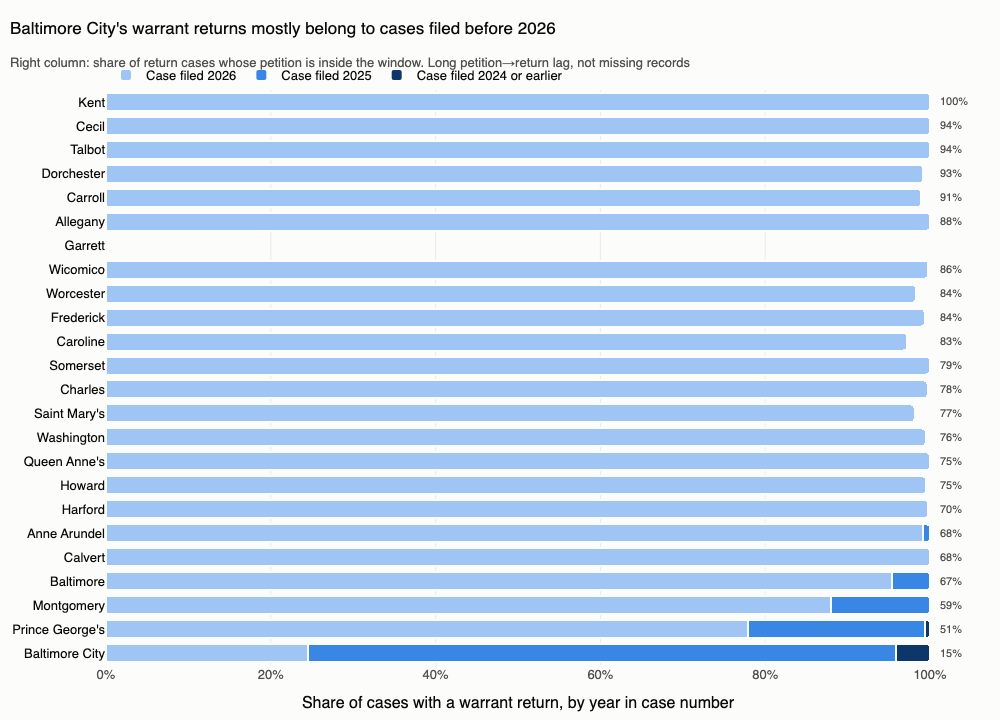

In [6]:
link = q(r"""
    WITH rc AS (
        SELECT raw_county AS county, clean_case_number,
               BOOL_OR(raw_event_type ILIKE 'Petition%') AS has_petition,
               BOOL_OR(raw_event_type NOT ILIKE 'Petition%') AS has_return,
               ANY_VALUE(TRY_CAST(REGEXP_EXTRACT(clean_case_number, '^D-\d+-[A-Z]+-(\d{2})-', 1) AS INT)) AS yy
        FROM raw_court_events GROUP BY 1, 2
    )
    SELECT county,
           CASE WHEN yy IS NULL THEN 'Unparsed' WHEN yy <= 24 THEN '2024 or earlier'
                WHEN yy = 25 THEN '2025' ELSE '2026' END AS case_year,
           COUNT(*) AS n, SUM(has_petition::INT) AS linked
    FROM rc WHERE has_return GROUP BY 1, 2
""")
link = link[link.case_year != "Unparsed"]  # <1.3% of return cases in any county
tot = link.groupby("county")[["n", "linked"]].sum()
link["share"] = link.n / link.county.map(tot.n)
link["link_rate"] = link.county.map(tot.linked / tot.n)
link = suppress(link, ["n", "linked"])
link.loc[link.n.isna(), "share"] = pd.NA
assert_public_safe(link, "return_linkage", ["n", "linked"])
order = (tot.linked / tot.n).sort_values(ascending=False).index.tolist()

fig = go.Figure()
# Ordinal: older case years darker
for yr, color in [("2026", BLUES[1]), ("2025", BLUES[3]), ("2024 or earlier", BLUES[6])]:
    d = link[link.case_year == yr].set_index("county").reindex(order)
    fig.add_bar(y=d.index, x=d.share, name=f"Case filed {yr}", orientation="h",
                marker=dict(color=color, line=dict(color="#fcfcfb", width=2)),
                customdata=np.stack([d.n, d.link_rate.where(d.n.notna())], axis=1),
                hovertemplate="%{y}<br>" + yr + " case numbers: %{x:.1%} of return cases (%{customdata[0]:,})"
                              "<br>Linked to in-window petition: %{customdata[1]:.0%}<extra></extra>")
for county_, rate in (tot.linked / tot.n).items():
    if tot.n[county_] < K or tot.linked[county_] < K:
        continue  # rate would expose a <10 count
    fig.add_annotation(y=county_, x=1.01, xref="paper", text=f"{rate:.0%}", showarrow=False, xanchor="left",
                       font=dict(size=11, color=MUTED))
fig.add_annotation(y=1.0, yref="paper", x=1.01, text="<b>linked</b>", showarrow=False, xanchor="left",
                   yanchor="bottom", font=dict(size=11, color=MUTED))
fig.update_layout(barmode="stack", height=720, bargap=0.25, margin=dict(r=70),
                  yaxis=dict(tickfont=dict(color=INK), autorange="reversed"),
                  xaxis=dict(tickformat=".0%", title="Share of cases with a warrant return, by year in case number", range=[0, 1]))
subtitle(fig, "Baltimore City's warrant returns mostly belong to cases filed before 2026",
         "Right column: share of return cases whose petition is inside the window. Long petition→return lag, not missing records")

Exact duplicates don't change case-level flags (they are `MAX`/`MIN` rollups). They do inflate `event_count`, so treat `event_count` as "rows in extract", not "distinct court actions".

## 2. Case warehouse: who, where, how fast

From here on every query runs against the masked views: `v_analyst_cases` (hashed IDs, no address), aggregated before display, and the pre-suppressed `v_public_*` views.

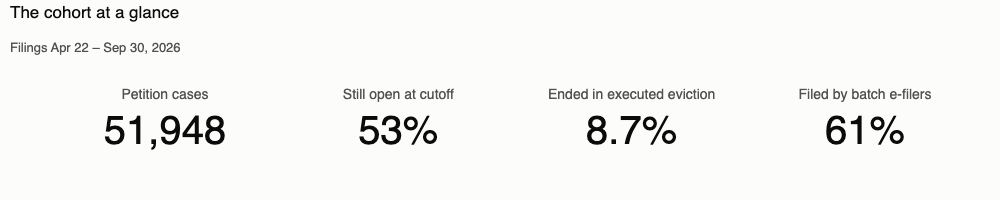

In [7]:
cases = q("""
    SELECT county_name, region, case_category, filing_date, filing_month, disposition_type, case_status,
           evicted_flag, batch_efiler_flag, days_observed, is_right_censored, extract_cutoff_date
    FROM v_analyst_cases
""")
assert len(cases) == cohort
cutoff = cases.extract_cutoff_date.max()

kpis = [
    ("Petition cases", len(cases), ",.0f", ""),
    ("Still open at cutoff", cases.is_right_censored.mean() * 100, ".0f", "%"),
    ("Ended in executed eviction", cases.evicted_flag.mean() * 100, ".1f", "%"),
    ("Filed by batch e-filers", cases.batch_efiler_flag.mean() * 100, ".0f", "%"),
]
fig = go.Figure()
for i, (label, val, fmt, suf) in enumerate(kpis):
    fig.add_trace(go.Indicator(mode="number", value=val, number=dict(valueformat=fmt, suffix=suf, font=dict(size=40)),
                               title=dict(text=f"<span style='color:{MUTED};font-size:14px'>{label}</span>"),
                               domain=dict(row=0, column=i)))
fig.update_layout(grid=dict(rows=1, columns=4), height=200, margin=dict(t=70, b=10))
subtitle(fig, "The cohort at a glance", f"Filings Apr 22 – {cutoff:%b %d, %Y}")

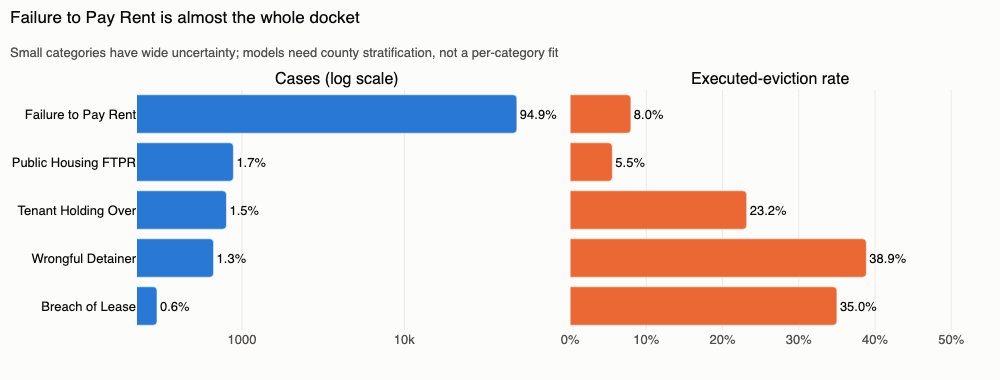

In [8]:
cat = (cases.groupby("case_category")
            .agg(n=("evicted_flag", "size"), evicted=("evicted_flag", "sum"))
            .reset_index().sort_values("n"))
cat["share"], cat["evict_rate"] = cat.n / cat.n.sum(), cat.evicted / cat.n
cat = suppress(cat, ["n", "evicted"])
assert_public_safe(cat, "category", ["n", "evicted"])

fig = make_subplots(rows=1, cols=2, shared_yaxes=True, horizontal_spacing=0.04,
                    subplot_titles=["Cases (log scale)", "Executed-eviction rate"])
fig.add_bar(y=cat.case_category, x=cat.n, orientation="h", marker_color=BLUE, row=1, col=1,
            text=[f"{s:.1%}" for s in cat.share], textposition="outside", cliponaxis=False,
            hovertemplate="%{y}<br>%{x:,} cases<extra></extra>")
fig.add_bar(y=cat.case_category, x=cat.evict_rate, orientation="h", marker_color=ORANGE, row=1, col=2,
            text=[f"{r:.1%}" for r in cat.evict_rate], textposition="outside", cliponaxis=False,
            hovertemplate="%{y}<br>%{x:.1%} evicted<extra></extra>")
fig.update_xaxes(type="log", dtick=1, row=1, col=1)
fig.update_xaxes(tickformat=".0%", range=[0, cat.evict_rate.max() * 1.35], row=1, col=2)
fig.update_layout(height=380, showlegend=False, yaxis=dict(tickfont=dict(color=INK)))
subtitle(fig, "Failure to Pay Rent is almost the whole docket",
         "Small categories have wide uncertainty; models need county stratification, not a per-category fit")

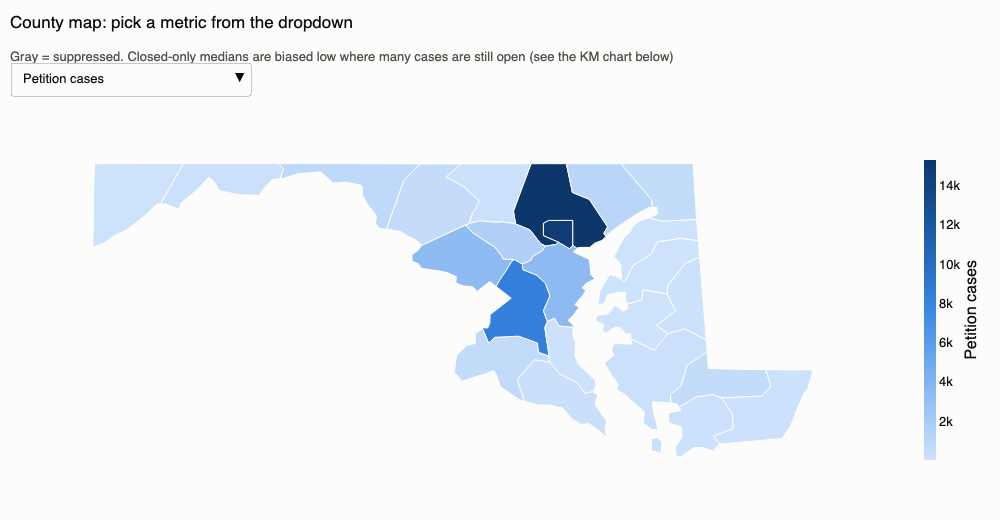

In [9]:
county = q("SELECT * FROM v_public_county_overall")
assert_public_safe(county, "v_public_county_overall", ["total_cases", "closed_cases", "evicted_cases"])

with_geo = gpd.read_file(f"zip://{ROOT / 'data/raw/cb_2023_us_county_20m.zip'}")
md_geo = with_geo[with_geo.STATEFP == "24"][["GEOID", "geometry"]].to_crs(4326)
geojson = json.loads(md_geo.to_json())

metrics = [
    ("total_cases", "Petition cases", ",.0f"),
    ("median_days_closed", "Median days to close (closed only)", ".0f"),
    ("clearance_rate_pct", "Closed by cutoff (%)", ".1f"),
    ("eviction_rate_pct", "Executed evictions (%)", ".1f"),
    ("batch_efiler_pct", "Batch e-filer share (%)", ".1f"),
]
hover = "<b>%{customdata[0]}</b><br>%{customdata[1]}: %{z:,.1f}<extra></extra>"

fig = go.Figure()
# Gray base layer: suppressed / missing counties stay visible instead of disappearing
fig.add_choropleth(geojson=geojson, featureidkey="properties.GEOID", locations=county.jurisdiction_fips,
                   z=[0] * len(county), colorscale=[[0, "#e4e3de"], [1, "#e4e3de"]], showscale=False,
                   marker_line=dict(color="white", width=1), customdata=county[["county_name"]],
                   hovertemplate="<b>%{customdata[0]}</b><br>suppressed (&lt;10)<extra></extra>")
col, label, _ = metrics[0]
fig.add_choropleth(geojson=geojson, featureidkey="properties.GEOID", locations=county.jurisdiction_fips,
                   z=county[col], colorscale=BLUES, marker_line=dict(color="white", width=1),
                   colorbar=dict(title=dict(text=label, side="right"), thickness=12, len=0.8),
                   customdata=np.stack([county.county_name, [label] * len(county)], axis=1),
                   hovertemplate=hover)
fig.update_geos(fitbounds="locations", visible=False, bgcolor="rgba(0,0,0,0)")
fig.update_layout(
    height=520, margin=dict(t=110, l=10, r=10, b=10),
    updatemenus=[dict(
        type="dropdown", x=0, xanchor="left", y=1.12, yanchor="top", showactive=True,
        buttons=[dict(label=lbl, method="restyle",
                      args=[{"z": [county[c].tolist()],
                             "customdata": [np.stack([county.county_name, [lbl] * len(county)], axis=1).tolist()],
                             "colorbar.title.text": lbl}, [1]])
                 for c, lbl, _ in metrics])],
)
subtitle(fig, "County map: pick a metric from the dropdown",
         "Gray = suppressed. Closed-only medians are biased low where many cases are still open (see the KM chart below)")

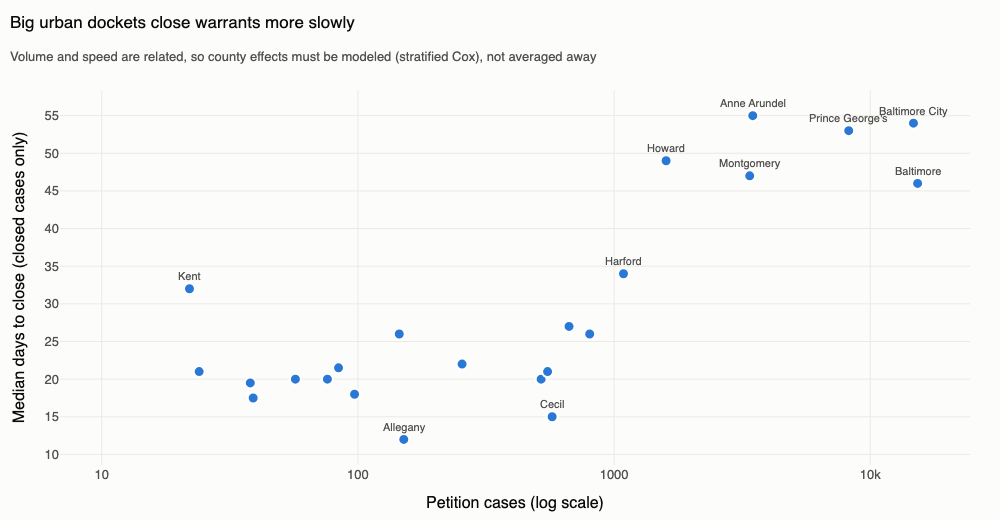

In [10]:
fig = go.Figure(go.Scatter(
    x=county.total_cases, y=county.median_days_closed, mode="markers",
    marker=dict(size=11, color=BLUE, line=dict(color="white", width=2)),
    customdata=county[["county_name", "clearance_rate_pct", "eviction_rate_pct"]],
    hovertemplate="<b>%{customdata[0]}</b><br>%{x:,} cases · median %{y:.0f} days (closed)"
                  "<br>closed by cutoff %{customdata[1]:.1f}% · evicted %{customdata[2]:.1f}%<extra></extra>",
))
# Label only the extremes; the crowded small-county cluster is readable on hover
for _, r in county[(county.total_cases > 1000) | (county.median_days_closed <= 15)
                   | (county.median_days_closed >= 30)].iterrows():
    fig.add_annotation(x=np.log10(r.total_cases), y=r.median_days_closed, text=r.county_name.replace(" County", ""),
                       showarrow=False, yshift=12, font=dict(size=11, color=MUTED))
fig.update_layout(height=520, showlegend=False,
                  xaxis=dict(type="log", dtick=1, title="Petition cases (log scale)"),
                  yaxis=dict(title="Median days to close (closed cases only)"))
subtitle(fig, "Big urban dockets close warrants more slowly",
         "Volume and speed are related, so county effects must be modeled (stratified Cox), not averaged away")

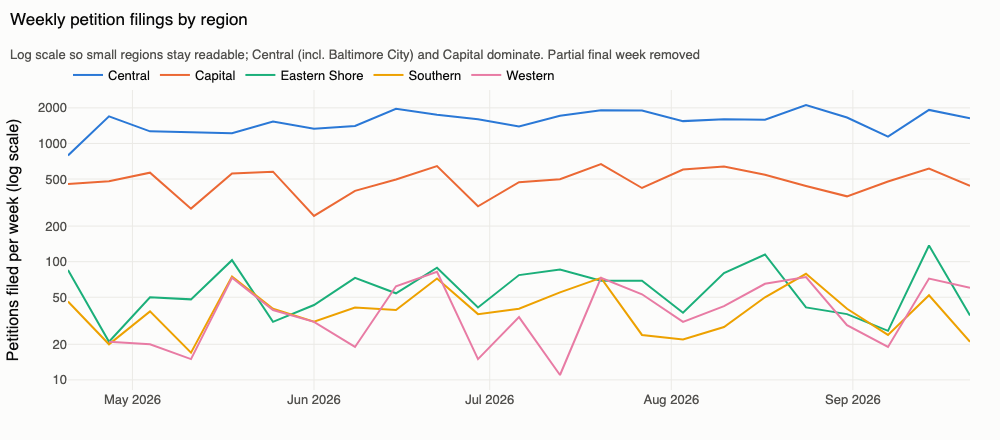

In [11]:
wk = cases.assign(week=cases.filing_date.dt.to_period("W").dt.start_time).groupby(["week", "region"]).size()
wk = suppress(wk.rename("n").reset_index(), ["n"])
assert_public_safe(wk, "weekly_region", ["n"])
last_full_week = wk.week.max()  # final week is partial at the cutoff
wk = wk[wk.week < last_full_week]

fig = go.Figure()
for i, region in enumerate(wk.groupby("region").n.sum().sort_values(ascending=False).index):
    d = wk[wk.region == region]
    fig.add_scatter(x=d.week, y=d.n, name=region, mode="lines", line=dict(width=2, color=[BLUE, ORANGE, AQUA, YELLOW, MAGENTA][i]),
                    hovertemplate="%{y:,} filings<extra>" + region + "</extra>")
fig.update_layout(height=440, hovermode="x unified",
                  yaxis=dict(type="log", title="Petitions filed per week (log scale)",
                             tickvals=[10, 20, 50, 100, 200, 500, 1000, 2000]),
                  xaxis=dict(hoverformat="Week of %b %d"))
subtitle(fig, "Weekly petition filings by region",
         "Log scale so small regions stay readable; Central (incl. Baltimore City) and Capital dominate. Partial final week removed")

### The core data trap: right censoring

More than half the cohort is still open at the cutoff. Recent filings have had less time to close, so a "closed-cases-only" summary keeps the fast cases and quietly drops the slow ones.

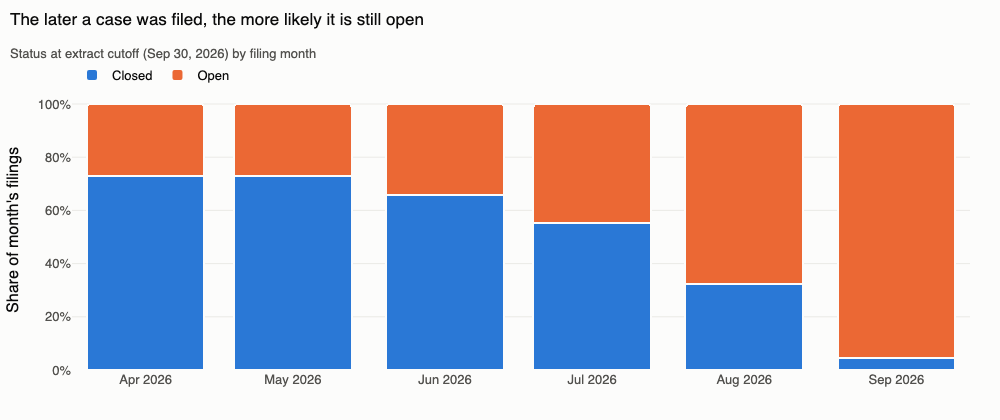

In [12]:
cm = (cases.groupby(["filing_month", "case_status"]).size().rename("n").reset_index())
cm["share"] = cm.n / cm.groupby("filing_month").n.transform("sum")
cm = suppress(cm, ["n"])
assert_public_safe(cm, "censoring_by_month", ["n"])

fig = go.Figure()
for status, color in [("Closed", BLUE), ("Open", ORANGE)]:
    d = cm[cm.case_status == status]
    fig.add_bar(x=d.filing_month, y=d.share, name=status, customdata=d.n,
                marker=dict(color=color, line=dict(color="#fcfcfb", width=2)),
                hovertemplate="%{x|%B}<br>" + status + ": %{y:.0%} (%{customdata:,} cases)<extra></extra>")
fig.update_layout(barmode="stack", height=420, yaxis=dict(tickformat=".0%", title="Share of month's filings"),
                  xaxis=dict(tickformat="%b %Y", dtick="M1"))
subtitle(fig, "The later a case was filed, the more likely it is still open",
         f"Status at extract cutoff ({cutoff:%b %d, %Y}) by filing month")

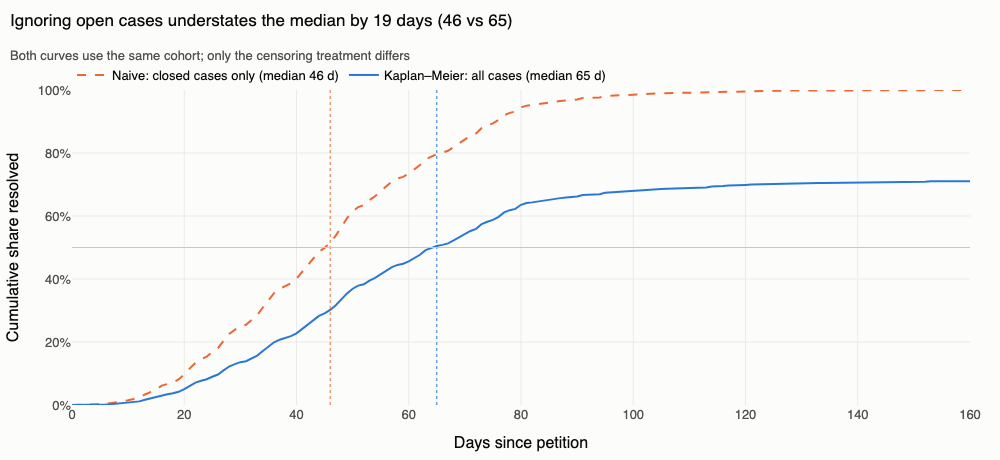

In [13]:
closed = cases[~cases.is_right_censored]
kmf = KaplanMeierFitter().fit(cases.days_observed, event_observed=~cases.is_right_censored)
days = np.arange(0, 161)
km_cdf = 1 - kmf.survival_function_at_times(days).to_numpy()
naive_cdf = np.searchsorted(np.sort(closed.days_observed), days, side="right") / len(closed)
naive_med, km_med = closed.days_observed.median(), kmf.median_survival_time_

fig = go.Figure()
fig.add_scatter(x=days, y=naive_cdf, name=f"Naive: closed cases only (median {naive_med:.0f} d)",
                line=dict(color=ORANGE, width=2, dash="dash"), hovertemplate="Day %{x}: %{y:.1%}<extra>Naive</extra>")
fig.add_scatter(x=days, y=km_cdf, name=f"Kaplan–Meier: all cases (median {km_med:.0f} d)",
                line=dict(color=BLUE, width=2), hovertemplate="Day %{x}: %{y:.1%}<extra>Kaplan–Meier</extra>")
for med, color in [(naive_med, ORANGE), (km_med, BLUE)]:
    fig.add_vline(x=med, line=dict(color=color, width=1, dash="dot"))
fig.add_hline(y=0.5, line=dict(color=GRAY, width=1))
fig.update_layout(height=460, hovermode="x unified",
                  xaxis=dict(title="Days since petition", range=[0, 160]),
                  yaxis=dict(title="Cumulative share resolved", tickformat=".0%", range=[0, 1]))
subtitle(fig, f"Ignoring open cases understates the median by {km_med - naive_med:.0f} days ({naive_med:.0f} vs {km_med:.0f})",
         "Both curves use the same cohort; only the censoring treatment differs")

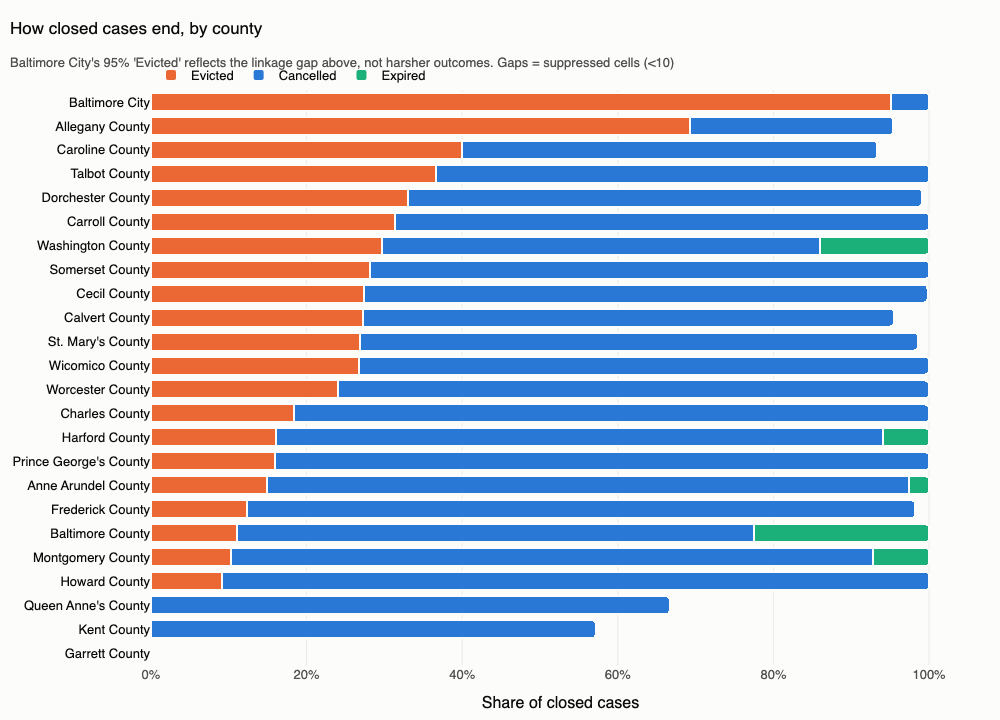

In [14]:
disp = (cases[cases.case_status == "Closed"].groupby(["county_name", "disposition_type"]).size()
        .unstack(fill_value=0).stack().rename("n").reset_index())
disp["share"] = disp.n / disp.groupby("county_name").n.transform("sum")
disp = suppress(disp, ["n"])
disp.loc[disp.n.isna(), "share"] = pd.NA
assert_public_safe(disp, "disposition_by_county", ["n"])
order = disp[disp.disposition_type == "Evicted"].sort_values("share", na_position="first").county_name.tolist()

fig = go.Figure()
for ev in ["Evicted", "Cancelled", "Expired"]:
    d = disp[disp.disposition_type == ev].set_index("county_name").reindex(order)
    fig.add_bar(y=d.index, x=d.share, name=ev, orientation="h", customdata=d.n,
                marker=dict(color=OUTCOME[ev], line=dict(color="#fcfcfb", width=2)),
                hovertemplate="%{y}<br>" + ev + ": %{x:.1%} (%{customdata:,} cases)<extra></extra>")
fig.update_layout(barmode="stack", height=720, bargap=0.25, yaxis=dict(tickfont=dict(color=INK)),
                  xaxis=dict(tickformat=".0%", title="Share of closed cases"))
subtitle(fig, "How closed cases end, by county",
         "Baltimore City's 95% 'Evicted' reflects the linkage gap above, not harsher outcomes. Gaps = suppressed cells (<10)")

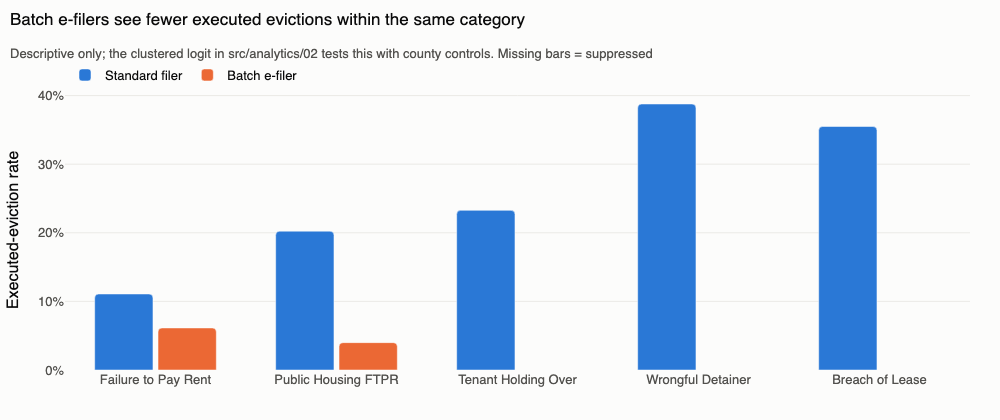

In [15]:
ef = (cases.assign(filer=np.where(cases.batch_efiler_flag, "Batch e-filer", "Standard filer"))
           .groupby(["case_category", "filer"])
           .agg(n=("evicted_flag", "size"), evicted=("evicted_flag", "sum")).reset_index())
ef["evict_rate"] = ef.evicted / ef.n
ef = suppress(ef, ["n", "evicted"])
ef.loc[ef.evicted.isna(), "evict_rate"] = pd.NA
assert_public_safe(ef, "efiler", ["n", "evicted"])
cat_order = ef.groupby("case_category").n.sum().sort_values(ascending=False).index.tolist()

fig = go.Figure()
for filer, color in [("Standard filer", BLUE), ("Batch e-filer", ORANGE)]:
    d = ef[ef.filer == filer].set_index("case_category").reindex(cat_order)
    fig.add_bar(x=d.index, y=d.evict_rate, name=filer, marker_color=color, customdata=d.n,
                hovertemplate="%{x}<br>%{y:.1%} evicted of %{customdata:,} cases<extra>" + filer + "</extra>")
fig.update_layout(barmode="group", height=420, bargap=0.3, bargroupgap=0.08,
                  yaxis=dict(tickformat=".0%", title="Executed-eviction rate"))
subtitle(fig, "Batch e-filers see fewer executed evictions within the same category",
         "Descriptive only; the clustered logit in src/analytics/02 tests this with county controls. Missing bars = suppressed")

## 3. Gold set: what the extraction task looks like

80 hand-annotated Maryland appellate opinions (public court records), split 20 dev / 60 test, with 6 target fields. The small-cell rule protects tenants in eviction records, so it doesn't apply to these published opinions.

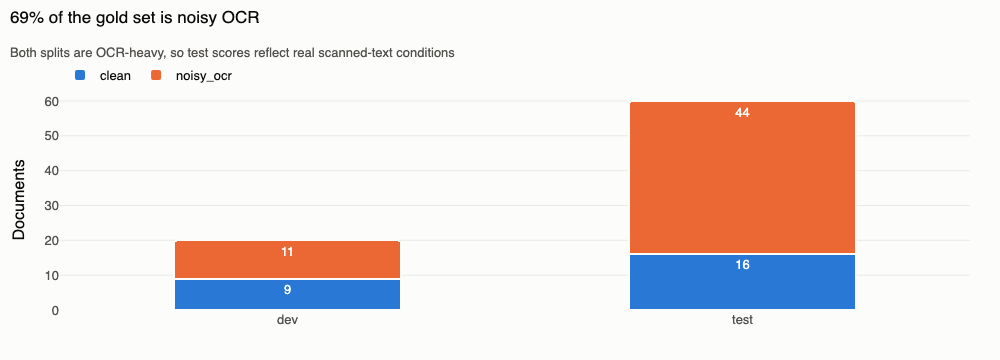

In [16]:
gold = pd.DataFrame([json.loads(l) for l in open(ROOT / "data/gold/gold_court_orders.jsonl")])
labels = pd.json_normalize(gold.gold)
g = pd.concat([gold.drop(columns="gold"), labels], axis=1)
g["words"] = g.text.str.split().str.len()

xt = g.groupby(["split", "text_quality"]).size().rename("n").reset_index()
fig = go.Figure()
for quality, color in [("clean", BLUE), ("noisy_ocr", ORANGE)]:
    d = xt[xt.text_quality == quality]
    fig.add_bar(x=d.split, y=d.n, name=quality, marker=dict(color=color, line=dict(color="#fcfcfb", width=2)),
                text=d.n, textposition="inside", hovertemplate="%{x}: %{y} docs<extra>" + quality + "</extra>")
fig.update_layout(barmode="stack", height=360, yaxis_title="Documents", bargap=0.5)
subtitle(fig, f"{(g.text_quality == 'noisy_ocr').mean():.0%} of the gold set is noisy OCR",
         "Both splits are OCR-heavy, so test scores reflect real scanned-text conditions")

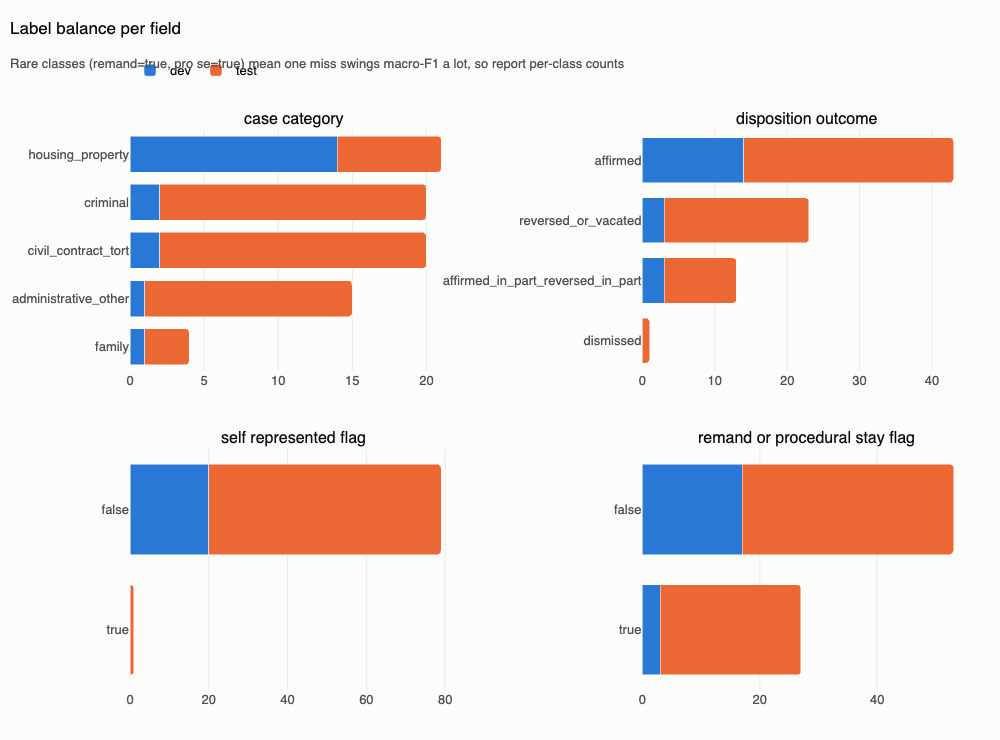

In [17]:
fields = ["case_category", "disposition_outcome", "self_represented_flag", "remand_or_procedural_stay_flag"]
fig = make_subplots(rows=2, cols=2, subplot_titles=[f.replace("_", " ") for f in fields],
                    horizontal_spacing=0.22, vertical_spacing=0.14)
for i, f in enumerate(fields):
    r, c = divmod(i, 2)
    counts = g.groupby([f, "split"]).size().unstack(fill_value=0).reindex(columns=["dev", "test"], fill_value=0)
    counts = counts.loc[counts.sum(axis=1).sort_values().index]
    for split, color in [("dev", BLUE), ("test", ORANGE)]:
        fig.add_bar(y=counts.index.astype(str), x=counts[split], name=split, orientation="h", marker_color=color,
                    legendgroup=split, showlegend=(i == 0), row=r + 1, col=c + 1,
                    hovertemplate="%{y}: %{x} docs<extra>" + split + "</extra>")
fig.update_layout(barmode="stack", height=740, bargap=0.25, margin=dict(t=130), legend=dict(y=1.08))
subtitle(fig, "Label balance per field",
         "Rare classes (remand=true, pro se=true) mean one miss swings macro-F1 a lot, so report per-class counts")

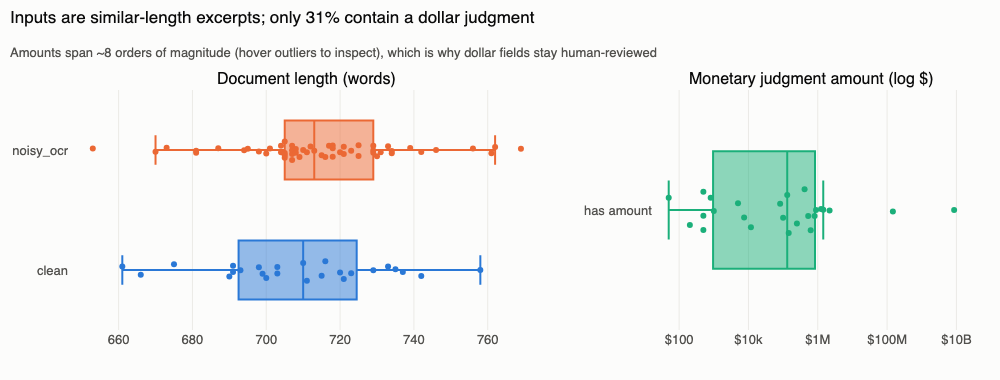

In [18]:
amt = pd.to_numeric(g.monetary_judgment_amount, errors="coerce")
fig = make_subplots(rows=1, cols=2, column_widths=[0.6, 0.4], horizontal_spacing=0.12,
                    subplot_titles=["Document length (words)", "Monetary judgment amount (log $)"])
for quality, color in [("clean", BLUE), ("noisy_ocr", ORANGE)]:
    d = g[g.text_quality == quality]
    fig.add_box(x=d.words, y=[quality] * len(d), name=quality, orientation="h", marker_color=color,
                boxpoints="all", jitter=0.4, pointpos=0, line_width=2, row=1, col=1,
                customdata=d[["doc_id", "ocr_noise_hits"]],
                hovertemplate="%{customdata[0]}<br>%{x:,} words · %{customdata[1]} OCR noise hits<extra></extra>")
fig.add_box(x=amt.dropna(), y=["has amount"] * amt.notna().sum(), orientation="h", marker_color=AQUA,
            boxpoints="all", jitter=0.4, pointpos=0, line_width=2, showlegend=False, row=1, col=2,
            customdata=g.loc[amt.notna(), "doc_id"], hovertemplate="%{customdata}<br>$%{x:,.0f}<extra></extra>")
fig.update_xaxes(type="log", tickprefix="$", row=1, col=2)
fig.update_layout(height=380, showlegend=False)
subtitle(fig, f"Inputs are similar-length excerpts; only {amt.notna().mean():.0%} contain a dollar judgment",
         "Amounts span ~8 orders of magnitude (hover outliers to inspect), which is why dollar fields stay human-reviewed")

**Why regex struggles on remand/stay.** A simple keyword rule flags any opinion that *mentions* "remand" or "stay". Opinions often quote the procedural history of a case ("the case was remanded in 2008..."), so the word turns up far more often than the label does.

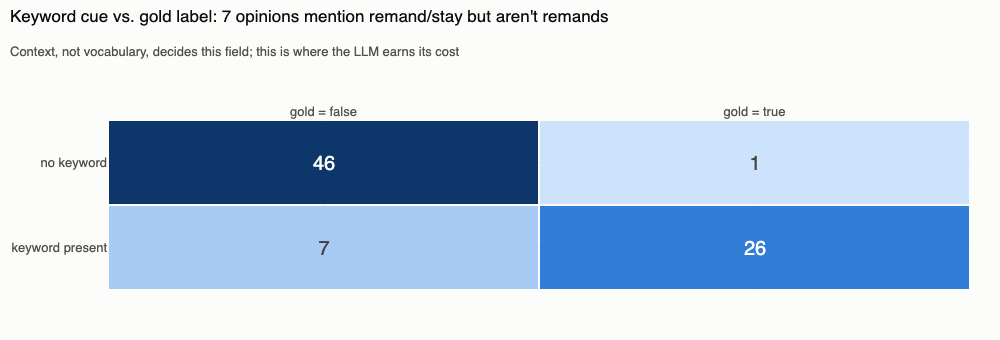

In [19]:
cue = g.text.str.contains(r"\bremand|\bstay(?:ed)?\b", case=False, regex=True)
ct = pd.crosstab(cue.map({True: "keyword present", False: "no keyword"}),
                 g.remand_or_procedural_stay_flag.astype(str).map(lambda v: f"gold = {v}"))
fig = go.Figure(go.Heatmap(z=ct.values, x=ct.columns, y=ct.index, colorscale=BLUES, showscale=False,
                           text=ct.values, texttemplate="%{text}", textfont=dict(size=20),
                           hovertemplate="%{y} · %{x}: %{z} docs<extra></extra>", xgap=2, ygap=2))
fig.update_layout(height=340, xaxis=dict(side="top"), margin=dict(t=120))
fp = ct.loc["keyword present"].get("gold = false", 0) if "keyword present" in ct.index else 0
subtitle(fig, f"Keyword cue vs. gold label: {fp} opinions mention remand/stay but aren't remands",
         "Context, not vocabulary, decides this field; this is where the LLM earns its cost")

## 4. Takeaways for modeling

| EDA finding | Decision it drives |
|---|---|
| About a quarter of cases are visible only as warrant returns, and they cluster at the window start | Restrict to the **petition cohort**; never impute filing dates |
| More than half the cohort is open at cutoff, and the share rises with filing month | **Kaplan–Meier / Cox** with right censoring; never report closed-only means as "time to disposition" |
| Volume and speed move together across counties | **County-stratified Cox** and **county-clustered SEs** in the logit |
| Baltimore City *does* record Cancelled/Expired returns, but 76% sit on pre-2026 case numbers; only ~15% link to an in-window petition | Its cohort "Pending"/"Evicted" mix is a **window-linkage artifact**; compare counties on a longer extract or mature cohort |
| Exact duplicate event rows exist | Case-level flags are safe (`MIN`/`MAX`); don't use `event_count` as a workload measure |
| Batch e-filers show lower eviction rates within category | Worth testing, **with county controls and a mature-cohort check** |
| Gold set is mostly noisy OCR; rare positive classes | Report **per-field, per-class** metrics; don't rely on averages alone |
| "Remand"/"stay" keywords over-fire | **Hybrid pipeline**: rules for docket IDs/standard rulings, LLM for remand/stay, humans for dollar amounts |

In [20]:
con.close()